# Load and Process Data

* Description: This cell loads and prepares NO2 and NDVI data from a 2019-2023 CSV file for Delhi to determine the NDVI increase needed for safe pollution levels.
* Initial Check: Displays the first 5 rows, total rows, and column names to verify the data.
* Point ID: Assigns location IDs by grouping every 5 rows and sorts by location and year.
* Changes: Calculates NO2_Change and NDVI_Change per location over time.
* Target Calculation: Defines a safe NO2 level (0.00004) and estimates the required NDVI_Change to reduce NO2 to this level, keeping only cases where NDVI increases.
* Output: Shows processed data summary and row counts.

In [ ]:
import pandas as pd

from google.colab import files
import io
import pandas as pd

# Load data
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith('.csv')]

if len(csv_files) != 1:
    raise ValueError("Please upload exactly one CSV file.")

df = pd.read_csv(io.BytesIO(uploaded[csv_files[0]]))

# Initial check
print(df.head(5))
print("Rows:", len(df))
print(df.columns)

# Adding point ID
df['point_id'] = df.index // 5
df = df.sort_values(['point_id', 'year'])

# Calculating changes and target NDVI_Change
df['NO2_Change'] = df.groupby('point_id')['NO2'].diff().shift(-1)
df['NDVI_Change'] = df.groupby('point_id')['NDVI'].diff().shift(-1)
df = df.dropna()

# Safe NO2 level
safe_no2 = 0.00004

# Calculating required NDVI_Change to reach safe NO2
df['target_ndvi_change'] = (df['NO2'] - safe_no2) / df['NO2'] * df['NDVI']
df = df[df['target_ndvi_change'] > 0]  # Removing -ve values

print("\nProcessed Data (First 5 rows):")
print(df.head(5))
print("Total Rows (with changes):", len(df))
print("Processed Rows:", len(df))

     year       NO2      NDVI
0  2019.0  0.000113  0.472539
1  2019.0  0.000091  0.219152
2  2019.0  0.000182  0.284309
3  2019.0  0.000112  0.396704
4  2019.0  0.000113  0.344996
Rows: 500
Index(['year', 'NO2', 'NDVI'], dtype='object')

Processed Data (First 5 rows):
     year       NO2      NDVI  point_id    NO2_Change  NDVI_Change  \
0  2019.0  0.000113  0.472539         0 -2.202349e-05    -0.253387   
1  2019.0  0.000091  0.219152         0  9.155605e-05     0.065157   
2  2019.0  0.000182  0.284309         0 -7.000469e-05     0.112396   
3  2019.0  0.000112  0.396704         0  9.832185e-07    -0.051709   
5  2019.0  0.000130  0.287822         1 -5.097635e-05     0.085957   

   target_ndvi_change  
0            0.305026  
1            0.122623  
2            0.221950  
3            0.255484  
5            0.199549  
Total Rows (with changes): 400
Processed Rows: 400


# Train Polynomial Regression

* Description: This cell trains a polynomial regression model to predict the NDVI_Change needed to achieve a safe NO2 level using current NO2 and NDVI data.
* Features and Target: Uses current NO2 and NDVI as features, and the calculated target NDVI_Change as the target variable.
* Polynomial Terms: Creates enhanced features (NO2, NDVI, NO2², NDVI², NO2 * NDVI) to capture complex relationships.
* Data Split: Randomly divides data into 80% training (180 rows) and 20% test (46 rows) sets.
* Training: Applies normal equations to compute weights that predict NDVI_Change.
* Prediction: Generates predicted NDVI_Change for both training and test sets.
* Evaluation: Calculates R² scores (train: 0.9834, test: 0.9808) to assess model accuracy.
* Saving: Stores test and predicted test NDVI_Change values for plotting.

In [ ]:
import numpy as np

# Features and target
X = df[['NO2', 'NDVI']].values  # Current NO2 and NDVI as features
y = df['target_ndvi_change'].values  # Target NDVI_Change to reach safe NO2

# Polynomial terms
X_poly = np.column_stack((
    X[:, 0],           # NO2
    X[:, 1],           # NDVI
    X[:, 0] ** 2,      # NO2²
    X[:, 1] ** 2,      # NDVI²
    X[:, 0] * X[:, 1]  # NO2 * NDVI
))
n_samples, n_features = X_poly.shape

# Splitting data
np.random.seed(42)
indices = np.random.permutation(n_samples)
train_size = int(0.8 * n_samples)
train_idx = indices[:train_size]
test_idx = indices[train_size:]
X_train, X_test = X_poly[train_idx], X_poly[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Polynomial Regression
X_train_with_ones = np.column_stack((np.ones(train_size), X_train))
weights = np.linalg.lstsq(X_train_with_ones, y_train, rcond=None)[0]

# Prediction
def predict(X, weights):
    X_with_ones = np.column_stack((np.ones(len(X)), X))
    return np.dot(X_with_ones, weights)

y_pred_train = predict(X_train, weights)
y_pred_test = predict(X_test, weights)

# R² calculation for accuracy
ss_tot_train = np.sum((y_train - np.mean(y_train)) ** 2)
ss_res_train = np.sum((y_train - y_pred_train) ** 2)
r2_train = 1 - ss_res_train / ss_tot_train

ss_tot_test = np.sum((y_test - np.mean(y_test)) ** 2)
ss_res_test = np.sum((y_test - y_pred_test) ** 2)
r2_test = 1 - ss_res_test / ss_tot_test

print("Train R²:", r2_train)
print("Test R²:", r2_test)

# Saved for plotting
np.save('y_test.npy', y_test)
np.save('y_pred_test.npy', y_pred_test)

Train R²: 0.9834357908417493
Test R²: 0.9808467217034512


# Plot Actual vs Predicted
* Description: This cell visualizes how well the model predicts the NDVI_Change needed to reach a safe NO2 level.
* Load Data: Retrieves actual and predicted NDVI_Change values from saved files.
* Plot: Creates a scatter plot comparing actual vs. predicted NDVI_Change, with a perfect prediction line.
* Labels: Adds titles, labels, and a legend for clarity.
Display: Shows the plot to evaluate model performance.

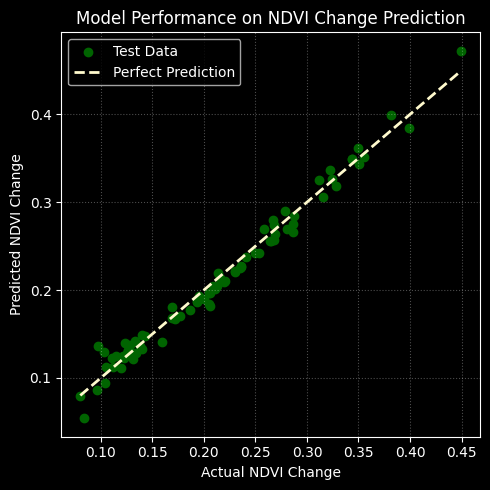

In [ ]:
import matplotlib.pyplot as plt

# Loading saved data
y_test = np.load('y_test.npy')
y_pred_test = np.load('y_pred_test.npy')

# Plot
plt.style.use('dark_background')
plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred_test, color='#006400', label='Test Data')  # Dark green
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='#FFFACD', linestyle='--', linewidth=2, label='Perfect Prediction')  # Pastel yellow
plt.xlabel('Actual NDVI Change', color='white')
plt.ylabel('Predicted NDVI Change', color='white')
plt.title('Model Performance on NDVI Change Prediction', color='white')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

# Applying Model to Different Scenarios
* Description: This cell applies the trained model to predict the NDVI level required to reduce NO2 to a safe level (0.00004) for various Kolkata scenarios.
* Test Cases: Defines scenarios with current NO2 and NDVI levels for Kolkata.
* Target: Sets a fixed safe NO2 level (0.00004) and maximum NDVI (0.7).
* Prediction Function: Uses polynomial features (NO2, NDVI, NO2², NDVI², NO2 * NDVI) to predict NDVI_Change.
* Iteration: Starts with a predicted NDVI_Change, iteratively adjusts it until the predicted NO2 reaches the target, stopping if NDVI exceeds 0.7.
* Output: Prints current NO2 and NDVI, target NDVI, estimated trees needed, and percentage reduction for each scenario.

In [ ]:
import numpy as np

# Test cases with current conditions
test_cases = [
    {'current_no2': 0.000116, 'current_ndvi': 0.289},  # Baseline Kolkata
    {'current_no2': 0.000150, 'current_ndvi': 0.300},  # Higher pollution
    {'current_no2': 0.000080, 'current_ndvi': 0.250},  # Lower pollution
    {'current_no2': 0.000130, 'current_ndvi': 0.270},  # Moderate pollution
    {'current_no2': 0.000090, 'current_ndvi': 0.280}   # Lower pollution
]

target_no2 = 0.00004  # Safe NO2 level
max_ndvi = 0.7        # Maximum realistic NDVI

for case in test_cases:
    current_no2 = case['current_no2']
    current_ndvi = case['current_ndvi']
    X_input = np.array([[current_no2, current_ndvi]])
    # Transform to polynomial features
    X_poly = np.column_stack((
        X_input[:, 0],          # NO2
        X_input[:, 1],          # NDVI
        X_input[:, 0] ** 2,     # NO2²
        X_input[:, 1] ** 2,     # NDVI²
        X_input[:, 0] * X_input[:, 1]  # NO2 * NDVI
    ))
    predicted_ndvi_change = predict(X_poly, weights)  # Use precomputed weights

    # Iterative refinement to reach target NO2
    ndvi_change = max(0, predicted_ndvi_change[0])
    predicted_no2 = current_no2
    while predicted_no2 > target_no2 and current_ndvi + ndvi_change <= max_ndvi:
        X_input = np.array([[current_no2, current_ndvi + ndvi_change]])
        X_poly = np.column_stack((
            X_input[:, 0],          # NO2
            X_input[:, 1],          # Updated NDVI
            X_input[:, 0] ** 2,     # NO2²
            X_input[:, 1] ** 2,     # NDVI²
            X_input[:, 0] * X_input[:, 1]  # NO2 * NDVI
        ))
        X_with_ones = np.column_stack((np.ones(1), X_poly))
        pred_ndvi_change = np.dot(X_with_ones, weights)
        predicted_no2 = current_no2 - pred_ndvi_change[0] * (current_no2 - target_no2) / current_ndvi
        ndvi_change += 0.0001

    final_ndvi = current_ndvi + ndvi_change
    reduction = ((current_no2 - predicted_no2) / current_no2) * 100 if current_no2 != 0 else 0
    trees_needed = ndvi_change * 1000

    print(f"Current NO2: {current_no2:.6f}, Current NDVI: {current_ndvi:.3f}")
    print(f"Target NDVI: {final_ndvi:.3f}, Trees Needed: {int(trees_needed)}, Reduction: {reduction:.1f}%")
    print("---")

Current NO2: 0.000116, Current NDVI: 0.289
Target NDVI: 0.486, Trees Needed: 196, Reduction: 73.0%
---
Current NO2: 0.000150, Current NDVI: 0.300
Target NDVI: 0.527, Trees Needed: 227, Reduction: 98.9%
---
Current NO2: 0.000080, Current NDVI: 0.250
Target NDVI: 0.524, Trees Needed: 274, Reduction: 50.0%
---
Current NO2: 0.000130, Current NDVI: 0.270
Target NDVI: 0.467, Trees Needed: 196, Reduction: 85.5%
---
Current NO2: 0.000090, Current NDVI: 0.280
Target NDVI: 0.523, Trees Needed: 243, Reduction: 55.6%
---
